# MLP NumPy y MNIST

Elias de Jesus Zuñiga de Leon · Matrícula 2430085

Este cuaderno contiene una copia completa de `red_mnist.py` y sus salidas reales. Ejecuta todas las celdas en orden, desde esta carpeta. La explicación y el análisis están en [README.md](README.md). Los archivos de entrada están en `datos/` cuando corresponda.

El código fuente principal se conserva en el archivo `.py`; `herramientas/generar_cuadernos.py` regenera y ejecuta este cuaderno después de cambiarlo.

In [1]:
import os, sys
from pathlib import Path
os.environ["MPLBACKEND"] = "Agg"
os.environ["OPENBLAS_NUM_THREADS"] = "1"
# Las rutas y argumentos equivalen a ejecutar el script desde esta carpeta.
__file__ = str(Path.cwd() / 'red_mnist.py')
sys.argv = [__file__]

In [2]:
"""MLP 784-100-10 con NumPy: ReLU, dropout, SSE y retropropagación."""
import argparse
import csv
import gzip
import hashlib
import json
import struct
from pathlib import Path
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
import numpy as np

HERE=Path(__file__).parent


def idx(nombre, magic):
    data=gzip.decompress((HERE/"datos"/nombre).read_bytes())
    encabezado=struct.unpack(">II",data[:8])
    if encabezado[0]!=magic: raise ValueError("Cabecera IDX incorrecta")
    if magic==2051:
        filas,columnas=struct.unpack(">II",data[8:16])
        x=np.frombuffer(data,dtype=np.uint8,offset=16).reshape(encabezado[1],filas*columnas)
        assert (filas,columnas)==(28,28)
        return x
    return np.frombuffer(data,dtype=np.uint8,offset=8)


def main():
    p=argparse.ArgumentParser(); p.add_argument("--epocas",type=int,default=100); p.add_argument("--muestras",type=int,default=1000); args=p.parse_args()
    out=HERE/"resultados"; out.mkdir(exist_ok=True)
    imagenes=idx("train-images-idx3-ubyte.gz",2051)
    etiquetas=idx("train-labels-idx1-ubyte.gz",2049)
    test=idx("t10k-images-idx3-ubyte.gz",2051).astype(np.float32)/255
    ytest=idx("t10k-labels-idx1-ubyte.gz",2049)
    assert imagenes.shape==(60000,784) and test.shape==(10000,784)
    rng=np.random.default_rng(2430085)
    x=imagenes[:args.muestras].astype(np.float32)/255; y=etiquetas[:args.muestras]
    target=np.eye(10,dtype=np.float32)[y]
    w1=rng.uniform(-.1,.1,(784,100)).astype(np.float32)
    w2=rng.uniform(-.1,.1,(100,10)).astype(np.float32)
    b1=np.zeros(100,dtype=np.float32); b2=np.zeros(10,dtype=np.float32)
    tasa=.08; batch=32; historial=[]
    print(f"MNIST: {len(imagenes)} imágenes originales de entrenamiento; prueba: {len(test)}.")
    print(f"Entrenamiento didáctico: {len(x)} imágenes, 784-100-10, {args.epocas} épocas, lote={batch}.")
    print("ReLU + dropout 0.5; pérdida = SSE promedio por imagen; semilla=2430085.")
    for epoca in range(1,args.epocas+1):
        orden=rng.permutation(len(x))
        for inicio in range(0,len(x),batch):
            ii=orden[inicio:inicio+batch]; xb=x[ii]
            z=xb@w1+b1; activacion=np.maximum(z,0)
            mascara=(rng.random(activacion.shape)>=.5).astype(np.float32)*2
            oculta=activacion*mascara
            logits=oculta@w2+b2
            d2=2*(logits-target[ii])/len(ii)
            d1=(d2@w2.T)*(z>0)*mascara
            # Todos los gradientes se calculan antes de modificar los pesos.
            gw2=oculta.T@d2; gw1=xb.T@d1
            w2-=tasa*gw2; b2-=tasa*d2.sum(axis=0)
            w1-=tasa*gw1; b1-=tasa*d1.sum(axis=0)
        if epoca==1 or epoca%5==0 or epoca==args.epocas:
            train_pred=np.maximum(x@w1+b1,0)@w2+b2
            test_pred=np.maximum(test@w1+b1,0)@w2+b2
            loss=float(np.mean(np.sum((train_pred-target)**2,axis=1)))
            acc=float(np.mean(train_pred.argmax(axis=1)==y)); acc_test=float(np.mean(test_pred.argmax(axis=1)==ytest))
            historial.append([epoca,loss,acc,acc_test])
            print(f"Época {epoca:3d}: SSE={loss:.4f}, exactitud train={acc:.2%}, test={acc_test:.2%}",flush=True)
    assert np.isfinite(w1).all() and np.isfinite(w2).all()
    pred=test_pred.argmax(axis=1)
    with (out/"entrenamiento.csv").open("w",newline="",encoding="utf-8") as f:
        w=csv.writer(f); w.writerow(["epoca","sse_train","exactitud_train","exactitud_test"]); w.writerows(historial)
    conf=np.zeros((10,10),dtype=int); np.add.at(conf,(ytest,pred),1)
    np.savetxt(out/"matriz_confusion.csv",conf,fmt="%d",delimiter=",")
    np.savez_compressed(out/"pesos.npz",w1=w1,w2=w2,b1=b1,b2=b2)
    fig,ax=plt.subplots(1,2,figsize=(11,4))
    h=np.array(historial); ax[0].plot(h[:,0],h[:,1]); ax[0].set(title="Error de entrenamiento",xlabel="Época",ylabel="SSE / imagen")
    ax[1].plot(h[:,0],h[:,2],label="Entrenamiento"); ax[1].plot(h[:,0],h[:,3],label="Prueba")
    ax[1].set(title="Exactitud sin dropout",xlabel="Época",ylabel="Proporción de aciertos",ylim=(0,1)); ax[1].legend()
    fig.tight_layout(); fig.savefig(out/"curvas.png",dpi=150); plt.close(fig)
    fig,ax=plt.subplots(2,5,figsize=(10,4))
    for i,a in enumerate(ax.flat):
        a.imshow(test[i].reshape(28,28),cmap="gray"); a.set_title(f"Real {ytest[i]} / pred {pred[i]}",color="green" if pred[i]==ytest[i] else "red"); a.axis("off")
    fig.tight_layout(); fig.savefig(out/"predicciones.png",dpi=150); plt.close(fig)
    metricas={"muestras_train":len(x),"muestras_test":len(test),"epocas":args.epocas,"exactitud_train":acc,"exactitud_test":acc_test,"sse_train":loss,"semilla":2430085,
              "sha256_pesos":hashlib.sha256((out/"pesos.npz").read_bytes()).hexdigest()}
    (out/"metricas.json").write_text(json.dumps(metricas,indent=2),encoding="utf-8")
    print(f"Evaluación final independiente: {int((pred==ytest).sum())}/{len(test)} aciertos.")


if __name__=="__main__": main()


MNIST: 60000 imágenes originales de entrenamiento; prueba: 10000.
Entrenamiento didáctico: 1000 imágenes, 784-100-10, 100 épocas, lote=32.
ReLU + dropout 0.5; pérdida = SSE promedio por imagen; semilla=2430085.
Época   1: SSE=0.5559, exactitud train=73.00%, test=66.59%


Época   5: SSE=0.3285, exactitud train=87.10%, test=77.83%


Época  10: SSE=0.2621, exactitud train=92.90%, test=84.25%


Época  15: SSE=0.1823, exactitud train=95.10%, test=84.64%


Época  20: SSE=0.1572, exactitud train=96.80%, test=86.45%


Época  25: SSE=0.1492, exactitud train=97.30%, test=87.04%


... (12 outputs left out)

Época  90: SSE=0.0702, exactitud train=99.60%, test=88.94%


Época  95: SSE=0.0610, exactitud train=99.70%, test=87.69%


Época 100: SSE=0.0543, exactitud train=99.70%, test=88.34%


Evaluación final independiente: 8834/10000 aciertos.


## Imágenes producidas por esta ejecución

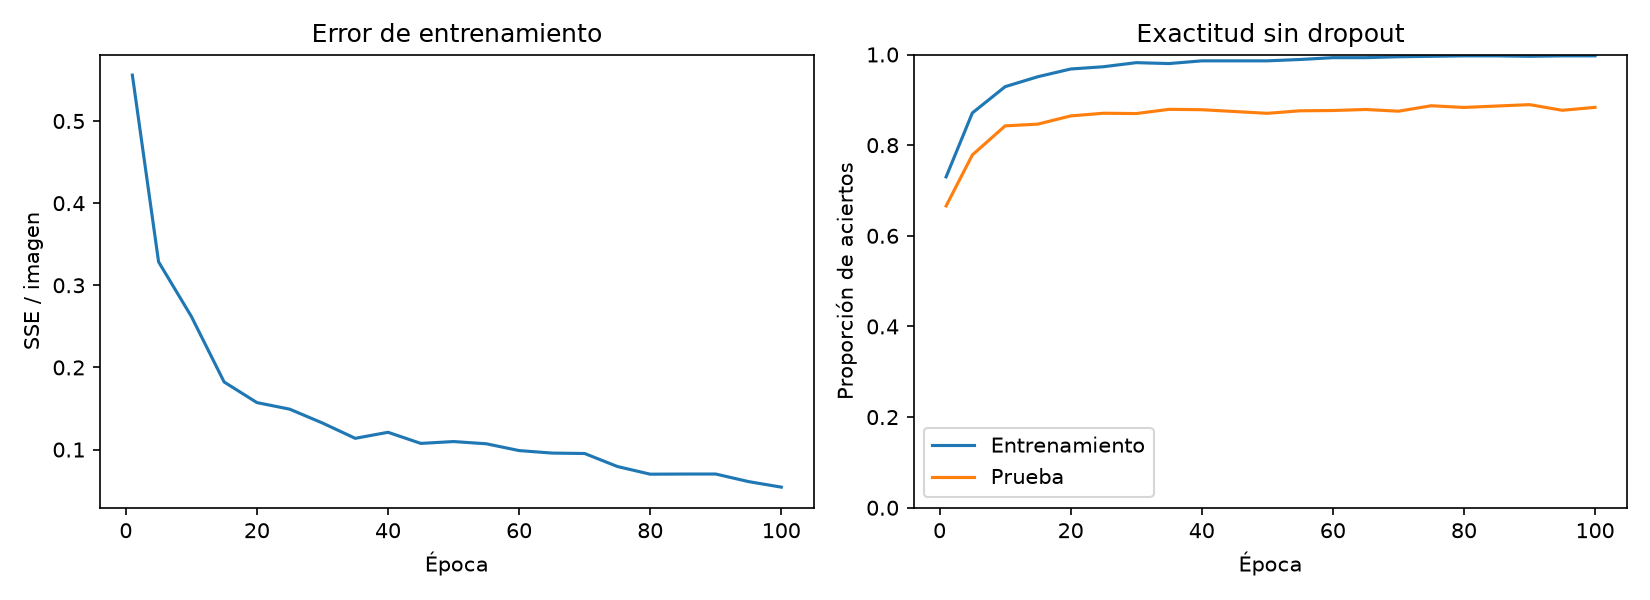

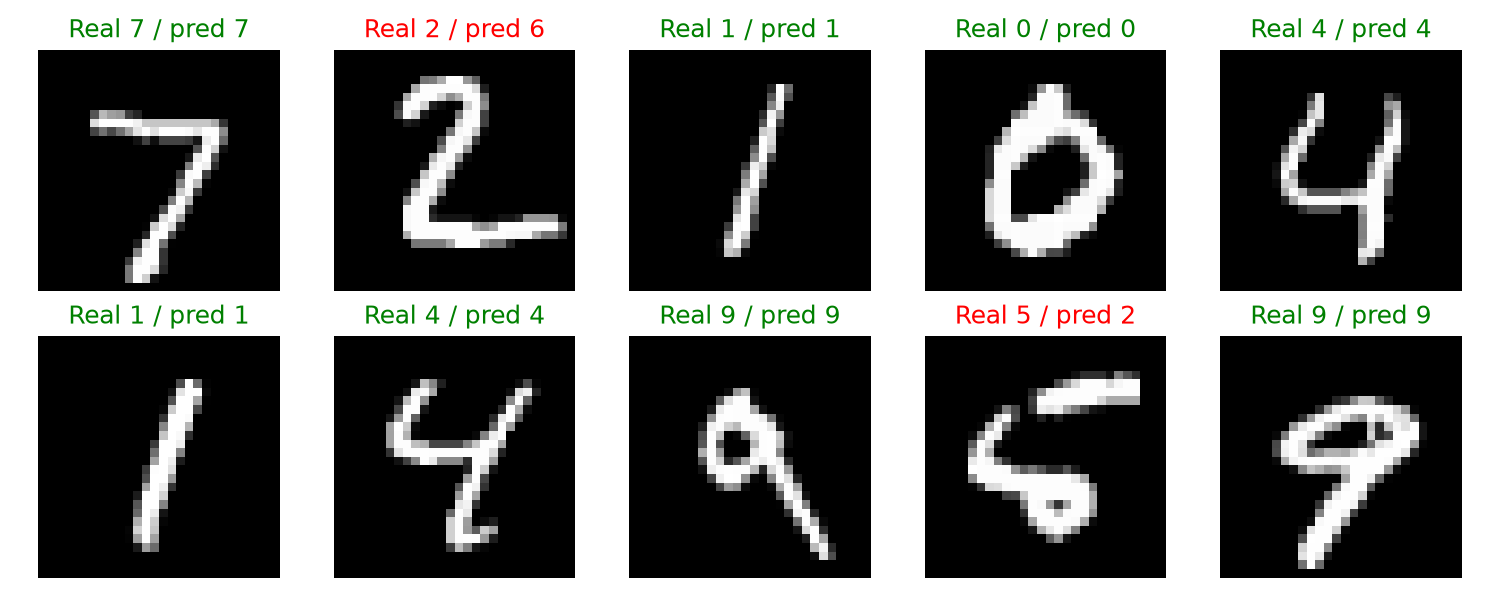

In [3]:
from IPython.display import display, Image
display(Image(filename='resultados/curvas.png'))
display(Image(filename='resultados/predicciones.png'))